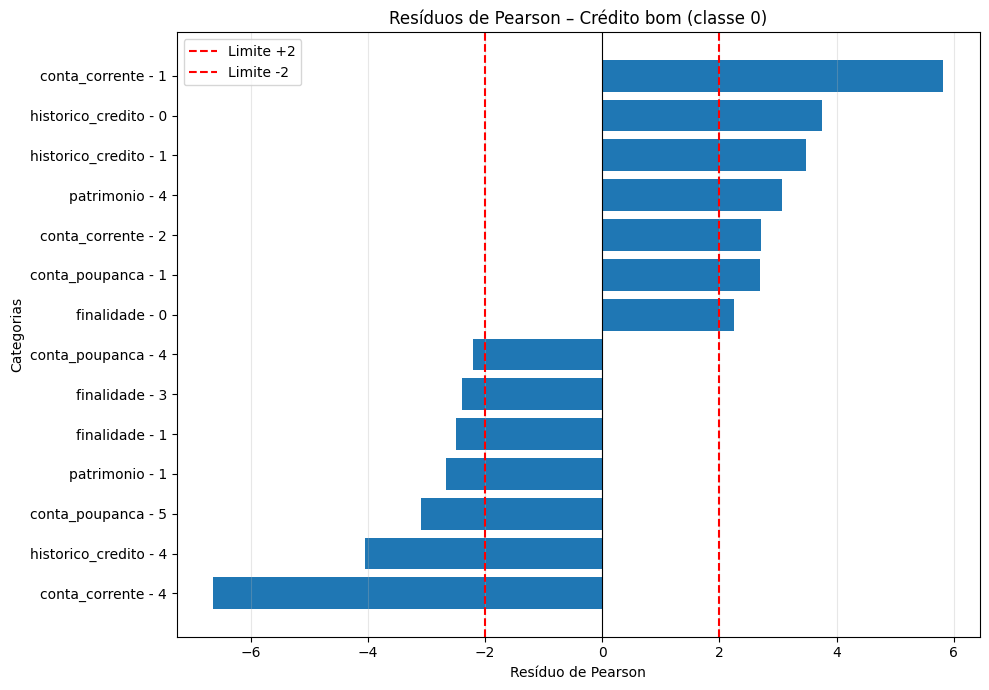

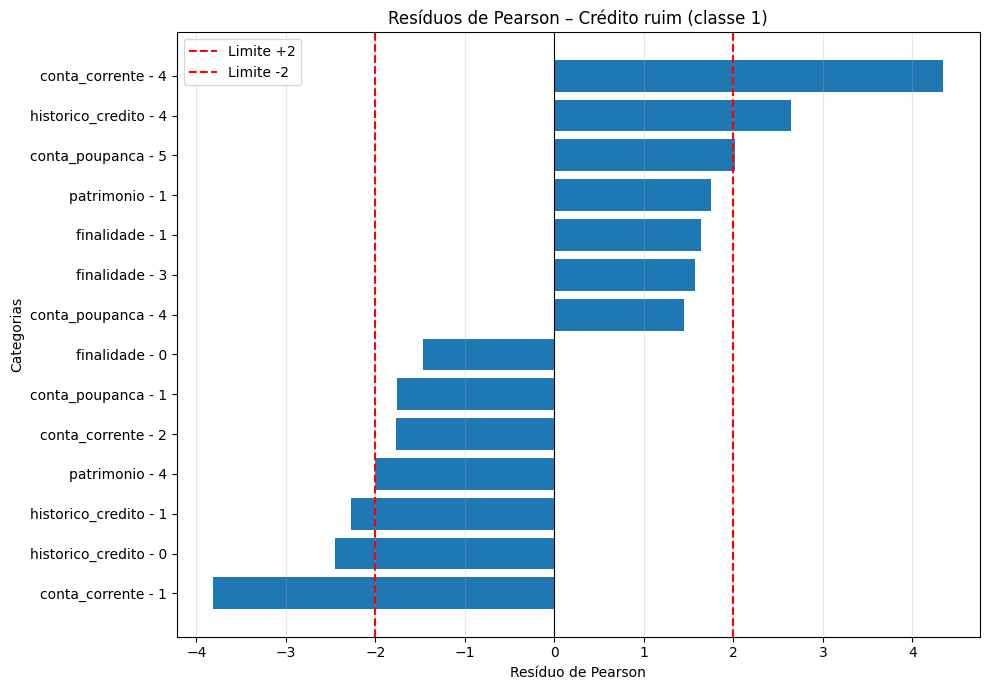

duracao                       valor_credito                   \
                  mean median    std min max          mean  median      std   
classe_credito                                                                
0                24.86   24.0  13.28   6  72       3938.13  2574.5  3535.82   
1                19.21   18.0  11.08   4  60       2985.44  2244.0  2401.50   

                            ... numero_creditos                       \
                min    max  ...            mean median   std min max   
classe_credito              ...                                        
0               433  18424  ...            1.37    1.0  0.56   1   4   
1               250  15857  ...            1.42    1.0  0.58   1   4   

               dependentes                       
                      mean median   std min max  
classe_credito                                   
0                     1.85    2.0  0.36   1   2  
1                     1.84    2.0  0.36   1   2  

[2 rows x 25 columns]

,count
classe_credito,
1,700
0,300



Distribuição final da classe de crédito:


,count
classe_credito,
0,300
1,700



Valores ausentes por variável:


,Valores ausentes
conta_corrente,0
duracao,0
historico_credito,0
finalidade,0
valor_credito,0
conta_poupanca,0
tempo_emprego,0
taxa_parcela,0
estado_civil_sexo,0
fiador,0



Análise exploratória de dados concluída.


In [ ]:

# ============================================================
# APÊNDICE A – CÓDIGO PYTHON
# ANÁLISE EXPLORATÓRIA DE DADOS – GERMAN CREDIT
# ============================================================

# ------------------------------------------------------------
# 1. IMPORTAÇÃO DAS BIBLIOTECAS E CARREGAMENTO DOS DADOS
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler

uploaded = files.upload()

df = pd.read_csv('german_credit_pt_1.csv')

display(df.head())

# Conferência da classificação de crédito
print("Distribuição da classe de crédito:")
print(df['classe_credito'].value_counts().sort_index())

assert set(df['classe_credito'].dropna().unique()) == {0, 1}
assert (df['classe_credito'] == 0).sum() == 300
assert (df['classe_credito'] == 1).sum() == 700

print("\nCodificação confirmada:")
print("0 = Crédito bom")
print("1 = Crédito ruim")


# ============================================================
# 2. ANÁLISE DAS VARIÁVEIS QUANTITATIVAS
# ============================================================

variaveis_quant = [
    'duracao',
    'valor_credito',
    'idade',
    'numero_creditos',
    'dependentes'
]

dados_quant = df[variaveis_quant].copy()

# 2.1 Estatísticas descritivas

estatisticas = dados_quant.describe().T

estatisticas['assimetria'] = dados_quant.skew()
estatisticas['curtose'] = dados_quant.kurtosis()

display(estatisticas)


# 2.2 Histogramas

fig, axes = plt.subplots(3, 2, figsize=(13, 8))

for i, var in enumerate(variaveis_quant):

    ax = axes.flat[i]

    ax.hist(
        dados_quant[var].dropna(),
        bins=13,
        edgecolor='black'
    )

    ax.set_title(var)
    ax.set_xlabel('')
    ax.set_ylabel('Frequência')
    ax.grid(axis='y', alpha=0.3)

axes.flat[5].set_visible(False)

plt.tight_layout()
plt.show()


# 2.3 Boxplots individuais

for variavel in variaveis_quant:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=dados_quant[variavel])

    plt.title(f'Boxplot de {variavel}')
    plt.xlabel(variavel)

    plt.tight_layout()
    plt.show()


# 2.4 Padronização das variáveis quantitativas

scaler = StandardScaler()

dados_padronizados = pd.DataFrame(
    scaler.fit_transform(dados_quant),
    columns=variaveis_quant
)

plt.figure(figsize=(10, 5))

sns.boxplot(data=dados_padronizados)

plt.title('Boxplots das variáveis quantitativas padronizadas')
plt.xlabel('Variáveis')
plt.ylabel('Valor padronizado (z-score)')

plt.tight_layout()
plt.show()


# 2.5 Correlação de Pearson

corr_pearson = dados_quant.corr(method='pearson')

display(corr_pearson)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Matriz de correlação de Pearson')
plt.tight_layout()
plt.show()


# 2.6 Correlação de Spearman

corr_spearman = dados_quant.corr(method='spearman')

display(corr_spearman)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Matriz de correlação de Spearman')
plt.tight_layout()
plt.show()


# 2.7 Comparação entre Pearson e Spearman

comparacao_corr = pd.DataFrame({
    'Pearson': corr_pearson.stack(),
    'Spearman': corr_spearman.stack()
})

display(comparacao_corr)


# 2.8 Relações entre as variáveis quantitativas

sns.pairplot(
    dados_quant,
    diag_kind='hist'
)

plt.show()


# ============================================================
# 3. ANÁLISE DAS VARIÁVEIS QUALITATIVAS ORDINAIS
# ============================================================

variaveis_ordinais = [
    'conta_corrente',
    'historico_credito',
    'conta_poupanca',
    'tempo_emprego',
    'taxa_parcela',
    'tempo_moradia',
    'patrimonio'
]


# 3.1 Frequências, mediana e quartis

for var in variaveis_ordinais:

    print(f'\nVariável: {var}')

    freq = df[var].value_counts().sort_index()

    perc = (
        df[var].value_counts(normalize=True)
        .sort_index() * 100
    )

    tabela = pd.DataFrame({
        'Frequência': freq,
        'Percentual (%)': perc.round(2)
    })

    display(tabela)

    print(f'Mediana: {df[var].median()}')
    print(f'Q1: {df[var].quantile(0.25)}')
    print(f'Q3: {df[var].quantile(0.75)}')


# 3.2 Gráficos de barras das variáveis ordinais

for var in variaveis_ordinais:

    frequencias = df[var].value_counts().sort_index()

    plt.figure(figsize=(7, 4))

    plt.bar(
        frequencias.index.astype(str),
        frequencias.values
    )

    plt.title(f'Distribuição de {var}')
    plt.xlabel('Categoria')
    plt.ylabel('Frequência')

    plt.tight_layout()
    plt.show()


# 3.3 Correlação de Spearman entre variáveis ordinais

correlacao_spearman = (
    df[variaveis_ordinais].corr(method='spearman')
)

display(correlacao_spearman.round(3))

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlacao_spearman,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlação de Spearman entre variáveis ordinais')
plt.tight_layout()
plt.show()


# ============================================================
# 4. ANÁLISE DAS VARIÁVEIS QUALITATIVAS
# ============================================================

variaveis_qualitativas = [
    'conta_corrente',
    'historico_credito',
    'finalidade',
    'conta_poupanca',
    'tempo_emprego',
    'estado_civil_sexo',
    'fiador',
    'patrimonio',
    'outros_creditos',
    'tipo_moradia',
    'profissao',
    'telefone',
    'trabalhador_estrangeiro'
]

# 4.1 Frequências e tabelas de contingência

for var in variaveis_qualitativas:

    dados = df[[var, 'classe_credito']].dropna()

    print(f'\n{"="*50}')
    print(f'Variável: {var}')
    print(f'{"="*50}')

    freq = dados[var].value_counts().sort_index()

    display(freq.to_frame('Frequência'))

    tabela = pd.crosstab(
        dados[var],
        dados['classe_credito']
    ).reindex(columns=[0, 1], fill_value=0)

    tabela.columns = [
        'Crédito bom (0)',
        'Crédito ruim (1)'
    ]

    print("\nTabela de contingência:")
    display(tabela)

    percentual = pd.crosstab(
        dados[var],
        dados['classe_credito'],
        normalize='index'
    ).reindex(columns=[0, 1], fill_value=0) * 100

    percentual.columns = [
        'Crédito bom (0)',
        'Crédito ruim (1)'
    ]

    print("\nDistribuição percentual por categoria:")
    display(percentual.round(2))


# ============================================================
# 5. GRÁFICOS DAS PRINCIPAIS VARIÁVEIS QUALITATIVAS
# ============================================================

variaveis_principais = {
    'conta_corrente': 'Conta corrente',
    'historico_credito': 'Histórico de crédito',
    'conta_poupanca': 'Conta poupança',
    'finalidade': 'Finalidade do crédito',
    'patrimonio': 'Patrimônio'
}

cor_bom = '#4472C4'
cor_ruim = '#ED7D31'

for variavel, titulo in variaveis_principais.items():

    tabela = pd.crosstab(
        df[variavel],
        df['classe_credito']
    ).reindex(columns=[0, 1], fill_value=0)

    percentuais = tabela.div(
        tabela.sum(axis=1), axis=0
    ) * 100

    categorias = tabela.index.astype(str)
    x = np.arange(len(categorias))
    largura = 0.35

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.bar(
        x - largura/2,
        percentuais[0],
        largura,
        label='Crédito bom (0)',
        color=cor_bom
    )

    ax.bar(
        x + largura/2,
        percentuais[1],
        largura,
        label='Crédito ruim (1)',
        color=cor_ruim
    )

    for i in range(len(categorias)):

        ax.text(
            x[i] - largura/2,
            percentuais.iloc[i, 0] + 1,
            f'{tabela.iloc[i, 0]}\n{percentuais.iloc[i, 0]:.1f}%',
            ha='center',
            fontsize=9
        )

        ax.text(
            x[i] + largura/2,
            percentuais.iloc[i, 1] + 1,
            f'{tabela.iloc[i, 1]}\n{percentuais.iloc[i, 1]:.1f}%',
            ha='center',
            fontsize=9
        )

    ax.set_title(
        f'Classificação de crédito por {titulo.lower()}'
    )

    ax.set_xlabel(titulo)
    ax.set_ylabel('Percentual de clientes (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(categorias, rotation=0)
    ax.set_ylim(0, 115)

    ax.legend(title='Classe de crédito')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()


# ============================================================
# 6. TESTE DO QUI-QUADRADO E V DE CRAMÉR
# ============================================================

resultados = []

for var in variaveis_qualitativas:

    dados = df[[var, 'classe_credito']].dropna()

    tabela = pd.crosstab(
        dados[var],
        dados['classe_credito']
    ).reindex(columns=[0, 1], fill_value=0)

    chi2, p_valor, gl, esperadas = chi2_contingency(tabela)

    n = tabela.to_numpy().sum()
    r, c = tabela.shape

    v_cramer = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    resultados.append({
        'Variável': var,
        'Qui-quadrado': chi2,
        'Graus de liberdade': gl,
        'p-valor': p_valor,
        'V de Cramér': v_cramer,
        'Menor frequência esperada': esperadas.min()
    })

resultado_associacao = pd.DataFrame(resultados)

print("\nResultados dos testes de associação:")

display(resultado_associacao.round(4))


# ============================================================
# 7. RESÍDUOS DE PEARSON
# ============================================================

variaveis_residuos = [
    'conta_corrente',
    'historico_credito',
    'conta_poupanca',
    'finalidade',
    'patrimonio'
]

# Cálculo dos resíduos para as cinco variáveis selecionadas

residuos_por_variavel = {}

for var in variaveis_residuos:

    dados = df[[var, 'classe_credito']].dropna()

    tabela = pd.crosstab(
        dados[var],
        dados['classe_credito']
    ).reindex(columns=[0, 1], fill_value=0)

    chi2, p, gl, esperadas = chi2_contingency(tabela)

    residuos = (
        tabela.to_numpy() - esperadas
    ) / np.sqrt(esperadas)

    residuos = pd.DataFrame(
        residuos,
        index=tabela.index,
        columns=['Crédito bom (0)', 'Crédito ruim (1)']
    )

    residuos_por_variavel[var] = residuos

    print(f"\n{'='*55}")
    print(f"Resíduos de Pearson: {var}")
    print(f"{'='*55}")

    display(residuos.round(2))


# 7.1 Seleção das 14 categorias utilizadas nos gráficos

categorias_residuos = {
    'conta_corrente': ['1', '2', '4'],
    'historico_credito': ['0', '1', '4'],
    'conta_poupanca': ['1', '4', '5'],
    'finalidade': ['0', '1', '3'],
    'patrimonio': ['1', '4']
}

registros = []

for var, categorias in categorias_residuos.items():

    residuos = residuos_por_variavel[var]

    for categoria in categorias:

        for indice in residuos.index:

            if str(indice) == categoria:

                registros.append({
                    'Categoria': f'{var} - {categoria}',
                    'Classe 0': residuos.loc[
                        indice, 'Crédito bom (0)'
                    ],
                    'Classe 1': residuos.loc[
                        indice, 'Crédito ruim (1)'
                    ]
                })


df_residuos = pd.DataFrame(registros)


# 7.2 Gráficos dos resíduos – classe 0 e classe 1

for coluna, titulo in [
    ('Classe 0', 'Resíduos de Pearson – Crédito bom (classe 0)'),
    ('Classe 1', 'Resíduos de Pearson – Crédito ruim (classe 1)')
]:

    df_plot = df_residuos.sort_values(coluna)

    plt.figure(figsize=(10, 7))

    plt.barh(
        df_plot['Categoria'],
        df_plot[coluna]
    )

    plt.axvline(0, color='black', linewidth=0.8)
    plt.axvline(2, color='red', linestyle='--', label='Limite +2')
    plt.axvline(-2, color='red', linestyle='--', label='Limite -2')

    plt.xlabel('Resíduo de Pearson')
    plt.ylabel('Categorias')
    plt.title(titulo)

    plt.legend()
    plt.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()


# ============================================================
# 8. COMPARAÇÃO DAS VARIÁVEIS QUANTITATIVAS
#    POR CLASSE DE CRÉDITO
# ============================================================

comparacao = df.groupby('classe_credito')[variaveis_quant].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

display(comparacao.round(2))

display(df['classe_credito'].value_counts())


# ============================================================
# 9. VERIFICAÇÃO FINAL DOS DADOS
# ============================================================

print("\nDistribuição final da classe de crédito:")

display(
    df['classe_credito'].value_counts().sort_index()
)

print("\nValores ausentes por variável:")

display(
    df.isnull().sum().to_frame('Valores ausentes')
)

print("\nAnálise exploratória de dados concluída.")

# ============================================================
# FIM DO PROGRAMA
# ============================================================
